In [16]:
%load_ext autoreload
%autoreload 2


from util import *
from myalgorithm import algorithm



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:

problem_file = "C:/Users/hcy05/Downloads/baseline_20240720/TEST_K50_1.json"
timelimit = 30

# np.random.seed(1)

with open(problem_file, 'r') as f:
    prob = json.load(f)

K = prob['K']

ALL_ORDERS = [Order(order_info) for order_info in prob['ORDERS']]
ALL_RIDERS = [Rider(rider_info) for rider_info in prob['RIDERS']]

DIST = np.array(prob['DIST'])
for r in ALL_RIDERS:
    r.T = np.round(DIST/r.speed + r.service_time)

alg_start_time = time.time()

exception = None

solution = None
try:
    # Run algorithm!
    solution = algorithm(K, ALL_ORDERS, ALL_RIDERS, DIST, timelimit)
except Exception as e:
    exception = f'{e}'


alg_end_time = time.time()

with open(problem_file, 'r') as f:
    prob = json.load(f)

K = prob['K']

ALL_ORDERS = [Order(order_info) for order_info in prob['ORDERS']]
ALL_RIDERS = [Rider(rider_info) for rider_info in prob['RIDERS']]

DIST = np.array(prob['DIST'])
for r in ALL_RIDERS:
    r.T = np.round(DIST/r.speed + r.service_time)

checked_solution = solution_check(K, ALL_ORDERS, ALL_RIDERS, DIST, solution)

checked_solution['time'] = alg_end_time - alg_start_time
checked_solution['timelimit_exception'] = (alg_end_time - alg_start_time) > timelimit + 1 # allowing additional 1 second!
checked_solution['exception'] = exception

checked_solution['prob_name'] = prob['name']
checked_solution['prob_file'] = problem_file

checked_solution

{'total_cost': 234551.5,
 'avg_cost': 4691.03,
 'num_drivers': 30,
 'total_dist': 115792,
 'feasible': True,
 'infeasibility': None,
 'bundles': [['BIKE', [0, 1, 13], [0, 1, 13]],
  ['BIKE', [2, 8, 6], [2, 8, 6]],
  ['BIKE', [3, 10, 5], [3, 10, 5]],
  ['BIKE', [4, 31], [4, 31]],
  ['BIKE', [7, 25, 35], [7, 25, 35]],
  ['BIKE', [9, 15], [9, 15]],
  ['BIKE', [11, 32], [11, 32]],
  ['BIKE', [12], [12]],
  ['BIKE', [14, 36], [14, 36]],
  ['WALK', [16], [16]],
  ['WALK', [19], [19]],
  ['WALK', [20], [20]],
  ['WALK', [21], [21]],
  ['WALK', [22], [22]],
  ['WALK', [24], [24]],
  ['WALK', [30], [30]],
  ['WALK', [37], [37]],
  ['WALK', [38], [38]],
  ['WALK', [41], [41]],
  ['WALK', [42], [42]],
  ['CAR', [18, 27], [18, 27]],
  ['CAR', [26, 23], [26, 23]],
  ['CAR', [29, 47], [29, 47]],
  ['CAR', [33, 46], [33, 46]],
  ['CAR', [17, 34], [17, 34]],
  ['CAR', [39, 48], [39, 48]],
  ['CAR', [28, 40], [28, 40]],
  ['CAR', [43, 49], [43, 49]],
  ['CAR', [44], [44]],
  ['CAR', [45], [45]]],
 'tim

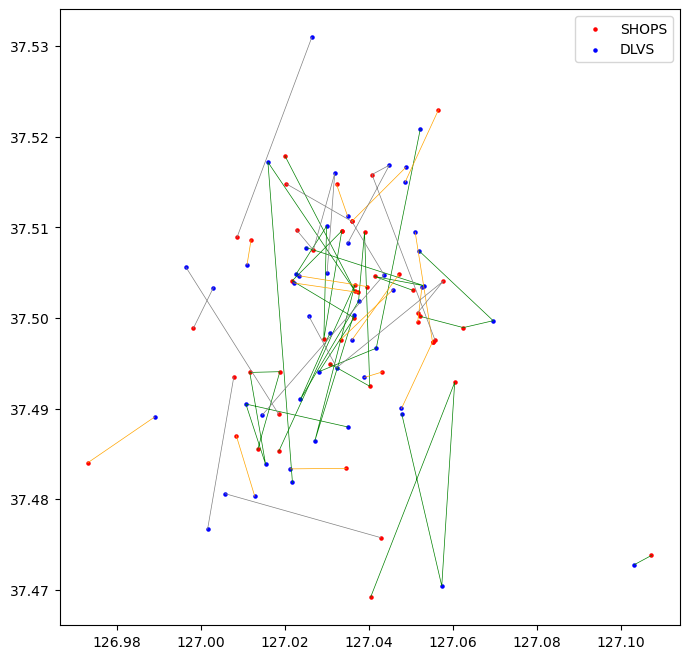

In [ ]:
draw_route_solution(ALL_ORDERS, checked_solution)

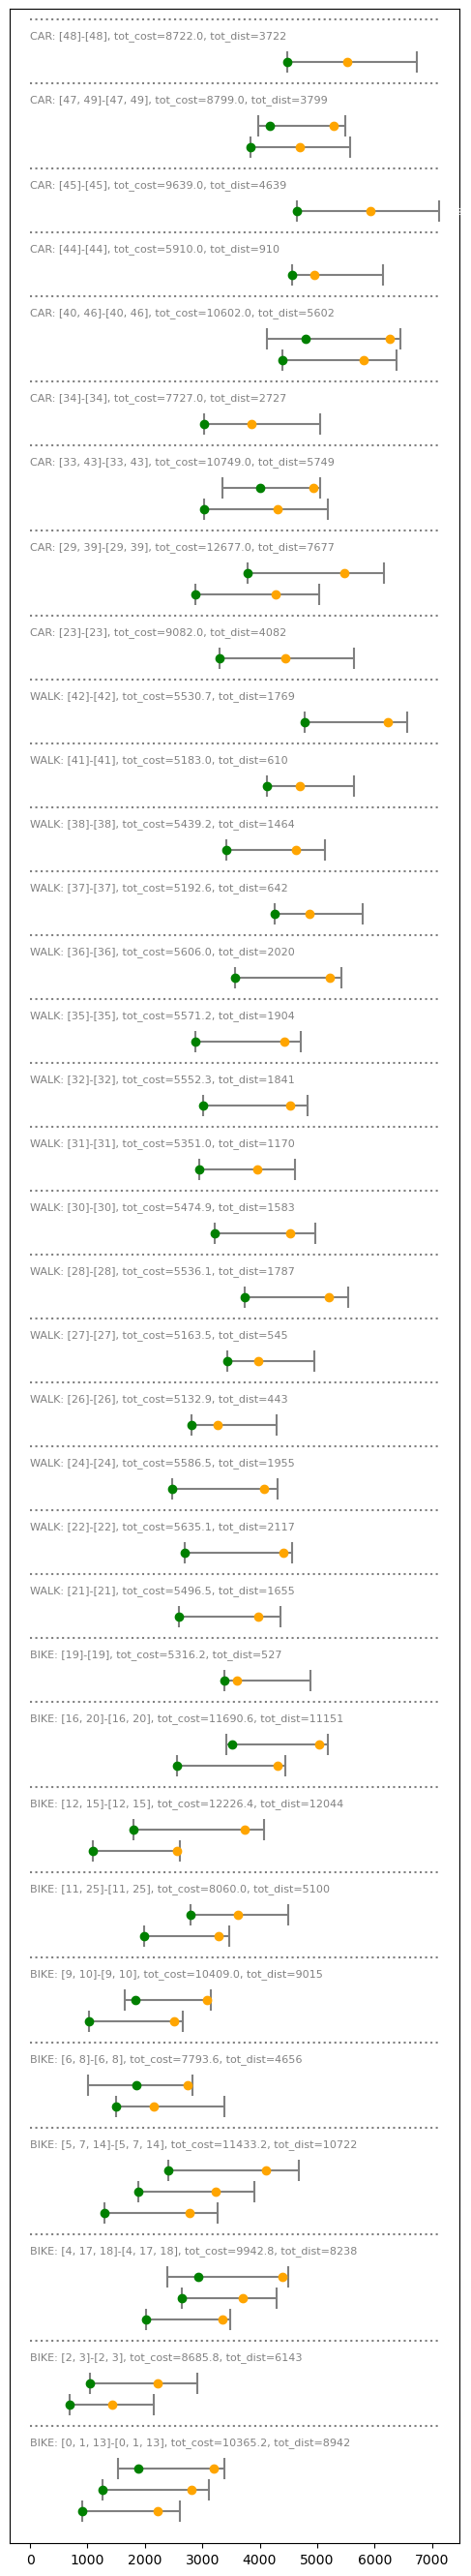

In [ ]:
draw_bundle_solution(ALL_ORDERS, ALL_RIDERS, DIST, checked_solution)